<a href="https://colab.research.google.com/github/KawDev21/analisis-data-perpustakaan-sqlite/blob/main/Forum_9_411232011_Sigit_Hadi_Pratama.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import os

if os.path.exists('perpustakaan.db'):
    os.remove('perpustakaan.db')

conn = sqlite3.connect('perpustakaan.db', timeout=10)
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON;")

cursor.execute('''
CREATE TABLE buku (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER
)
''')

cursor.execute('''
CREATE TABLE anggota (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nama TEXT NOT NULL,
    email TEXT NOT NULL UNIQUE
)
''')

cursor.execute('''
CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    id_anggota INTEGER,
    id_buku INTEGER,
    tgl_pinjam DATE NOT NULL,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
)
''')

data_buku = [
    ('Air Berapi: Kita Berteman Sudah Lama', 'Sindhunata', 2026),
    ('Seorang Anak yang Bersembunyi di Balik Topeng Superhero', 'dr. Andreas Kurniawan, Sp.KJ', 2026),
    ('Seporsi Mie Ayam Sebelum Mati', 'Brian Khrisna', 2025),
    ('The Let Them Theory', 'Mel Robbins & Sawyer Robbins', 2024),
    ('Carstenz', 'Doni Nurdiansyah', 2025)
]
cursor.executemany(
    "INSERT INTO buku (judul, penulis, tahun) VALUES (?, ?, ?)",
    data_buku
)

data_anggota = [
    ('Lulu Handayani', 'lulu@email.com'),
    ('Sigit Hadi Pratama', 'sigit@email.com'),
    ('Bagus Pamungkas', 'bagus@email.com')
]
cursor.executemany(
    "INSERT INTO anggota (nama, email) VALUES (?, ?)",
    data_anggota
)

data_peminjaman = [
    (1, 1, '2026-11-01', '2026-11-05'),
    (1, 3, '2026-11-03', '2026-11-10'),
    (2, 2, '2026-11-08', '2026-11-12'),
    (3, 5, '2026-11-15', None)
]
cursor.executemany(
    "INSERT INTO peminjaman (id_anggota, id_buku, tgl_pinjam, tgl_kembali) VALUES (?, ?, ?, ?)",
    data_peminjaman
)

conn.commit()
conn.close()
print("Seluruh data berhasil dimasukkan ke dalam tabel.")

Seluruh data berhasil dimasukkan ke dalam tabel.


In [21]:
conn = sqlite3.connect('perpustakaan.db')

query_1c = """
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id
"""
df_peminjaman = pd.read_sql_query(query_1c, conn)
print("Daftar Peminjaman Lengkap:")
display(df_peminjaman)

query_1d = """
SELECT
    a.nama AS nama_anggota,
    COUNT(p.id_buku) AS total_buku_dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY total_buku_dipinjam DESC
"""
df_total_pinjam = pd.read_sql_query(query_1d, conn)
print("\nTotal Buku Dipinjam per Anggota:")
display(df_total_pinjam)

Daftar Peminjaman Lengkap:


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Lulu Handayani,Air Berapi: Kita Berteman Sudah Lama,2026-11-01,2026-11-05
1,2,Lulu Handayani,Seporsi Mie Ayam Sebelum Mati,2026-11-03,2026-11-10
2,3,Sigit Hadi Pratama,Seorang Anak yang Bersembunyi di Balik Topeng ...,2026-11-08,2026-11-12
3,4,Bagus Pamungkas,Carstenz,2026-11-15,None



Total Buku Dipinjam per Anggota:


,nama_anggota,total_buku_dipinjam
0,Lulu Handayani,2
1,Sigit Hadi Pratama,1
2,Bagus Pamungkas,1


Hasil Eksplorasi Data Peminjaman:


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,durasi_hari,status
0,1,Lulu Handayani,Air Berapi: Kita Berteman Sudah Lama,2026-11-01,2026-11-05,4.0,Sudah Dikembalikan
1,2,Lulu Handayani,Seporsi Mie Ayam Sebelum Mati,2026-11-03,2026-11-10,7.0,Sudah Dikembalikan
2,3,Sigit Hadi Pratama,Seorang Anak yang Bersembunyi di Balik Topeng ...,2026-11-08,2026-11-12,4.0,Sudah Dikembalikan
3,4,Bagus Pamungkas,Carstenz,2026-11-15,NaT,NaN,Belum Dikembalikan



Rata-rata durasi peminjaman untuk buku yang sudah kembali: 5.00 hari


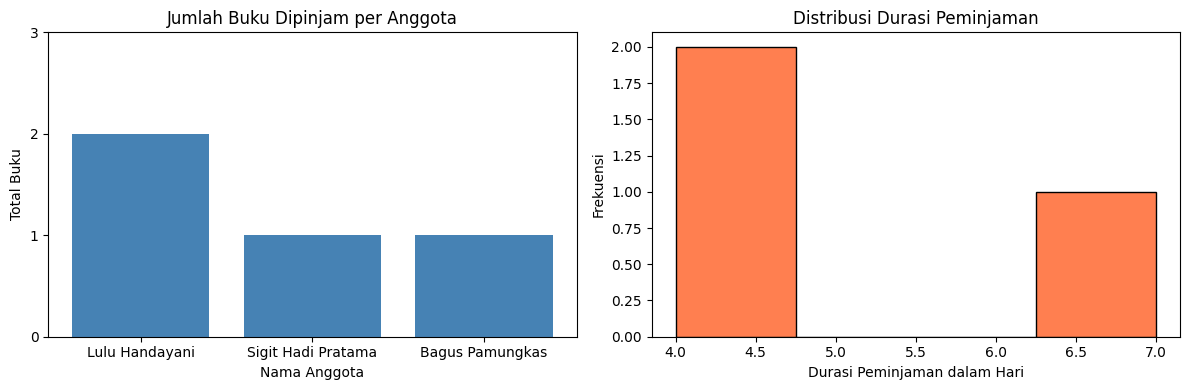

In [22]:
df_peminjaman['tgl_pinjam'] = pd.to_datetime(df_peminjaman['tgl_pinjam'])
df_peminjaman['tgl_kembali'] = pd.to_datetime(df_peminjaman['tgl_kembali'])

df_peminjaman['durasi_hari'] = (df_peminjaman['tgl_kembali'] - df_peminjaman['tgl_pinjam']).dt.days
df_peminjaman['status'] = df_peminjaman['tgl_kembali'].apply(
    lambda x: 'Belum Dikembalikan' if pd.isna(x) else 'Sudah Dikembalikan'
)

print("Hasil Eksplorasi Data Peminjaman:")
display(df_peminjaman)

rata_durasi = df_peminjaman['durasi_hari'].mean()
print(f"\nRata-rata durasi peminjaman untuk buku yang sudah kembali: {rata_durasi:.2f} hari")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(df_total_pinjam['nama_anggota'], df_total_pinjam['total_buku_dipinjam'], color='steelblue')
axes[0].set_title('Jumlah Buku Dipinjam per Anggota')
axes[0].set_xlabel('Nama Anggota')
axes[0].set_ylabel('Total Buku')
axes[0].set_yticks(range(0, df_total_pinjam['total_buku_dipinjam'].max() + 2))


durasi_valid = df_peminjaman['durasi_hari'].dropna()
axes[1].hist(durasi_valid, bins=4, color='coral', edgecolor='black')
axes[1].set_title('Distribusi Durasi Peminjaman')
axes[1].set_xlabel('Durasi Peminjaman dalam Hari')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

conn.close()